<a href="https://colab.research.google.com/github/nikki-mahendiyan/san-diego-climate-stats/blob/main/San_Diego_Climate_Work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
# Start from the main Colab folder and unzip the project
setwd("/content")
unzip("san-diego-climate-stats.zip")
setwd("san-diego-climate-stats")

# Check that the scripts, the data file, and the figures folder are all there
list.files(recursive = TRUE)

[1] "00_load_and_clean.R"            "01_san_diego_temperature.R"    
 [3] "02_san_diego_rainfall.R"        "03_matrix_least_squares.R"     
 [5] "data/san_diego_daily.csv"       "figures/annual_temperature.png"
 [7] "figures/rainfall_by_year.png"   "figures/rainfall_histogram.png"
 [9] "figures/summer_vs_winter.png"   "README.md"

In [22]:
# Annual average temperature for San Diego, 1940 to 2025.
# Fits a linear trend, compares 1940 to 1969 with 1996 to 2025,
# and checks summer and winter trends separately.
# This also runs 00_load_and_clean.R, which loads and checks the data.
source("01_san_diego_temperature.R")

Station: SAN DIEGO INTERNATIONAL AIRPORT, CA US 
Rows: 31409 
Date range: 1940-01-01 to 2025-12-31 
Calendar days with no row: 3 
[1] "1947-04-06" "1947-04-07" "1947-04-08"
Missing TMAX: 3 
Missing TMIN: 2 
Missing PRCP: 0 

Fewest valid days in any year: 362 

Annual average temperature (C), first and last 3 years:
   year     TAVG
1  1940 17.58183
2  1941 17.82438
3  1942 17.03616
84 2023 17.30973
85 2024 17.75984
86 2025 17.81198

Warmest year: 2014 at 19.77 C
Coolest year: 1948 at 16.27 C

Call:
lm(formula = TAVG ~ year_c, data = annual)

Residuals:
    Min      1Q  Median      3Q     Max 
-1.1933 -0.4973 -0.1117  0.3447  1.7900 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 17.762188   0.078216   227.1  < 2e-16 ***
year_c       0.012918   0.003151     4.1  9.5e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.7253 on 84 degrees of freedom
Multiple R-squared:  0.1668,	Adjusted R-squared:  0.1568

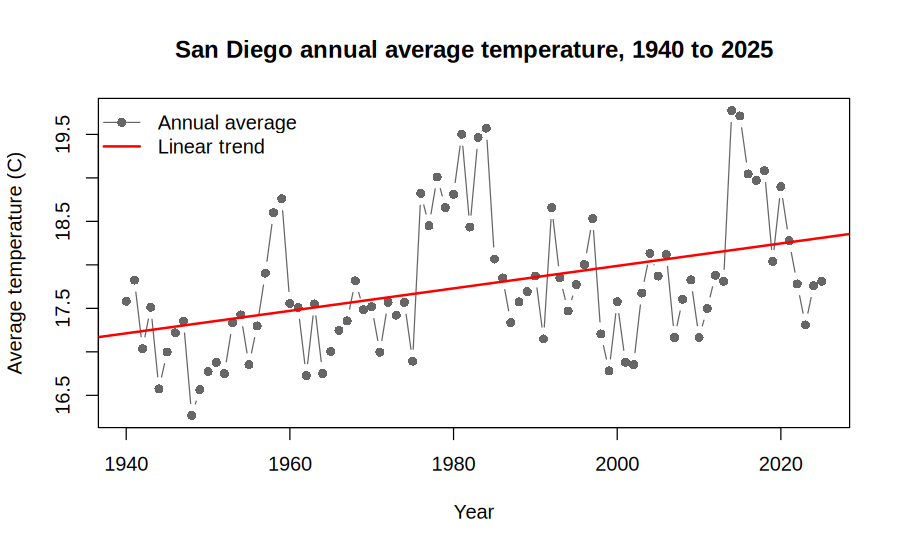

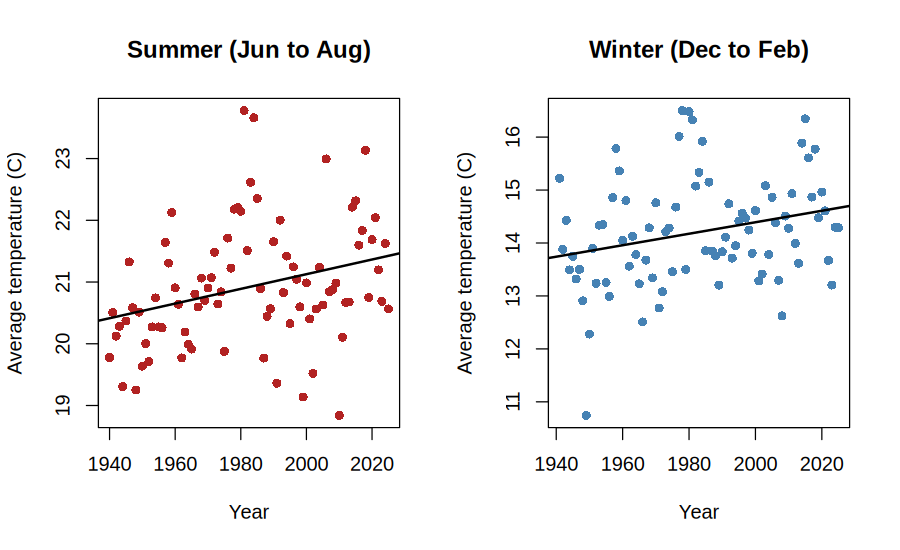

In [27]:
# Plot of annual average temperature with the trend line and summer vs winter side by side
IRdisplay::display_png(file = "figures/annual_temperature.png")
IRdisplay::display_png(file = "figures/summer_vs_winter.png")

In [24]:
# Rainfall totals by rain year (July to June), how much they vary
# From year to year, and whether there is a trend
source("02_san_diego_rainfall.R")

Station: SAN DIEGO INTERNATIONAL AIRPORT, CA US 
Rows: 31409 
Date range: 1940-01-01 to 2025-12-31 
Calendar days with no row: 3 
[1] "1947-04-06" "1947-04-07" "1947-04-08"
Missing TMAX: 3 
Missing TMIN: 2 
Missing PRCP: 0 

Rain years used: 1941 to 2025 
Number of rain years: 85 

Average rain year total: 251 mm ( 9.9 inches )
Median: 231 mm
Standard deviation: 114 mm
Years above 1.5 times the average: 11 
Years below half the average: 8 

Five wettest rain years:
   rain_year    mm   inches
2       1941 628.9 24.75984
66      2005 571.6 22.50394
39      1978 475.6 18.72441
54      1993 465.3 18.31890
44      1983 463.7 18.25591

Five driest rain years:
   rain_year    mm   inches
63      2002  76.0 2.992126
79      2018  86.7 3.413386
22      1961  88.1 3.468504
68      2007  98.2 3.866142
24      1963 101.7 4.003937

Call:
lm(formula = mm ~ year_c, data = rain)

Residuals:
    Min      1Q  Median      3Q     Max 
-169.29  -87.65  -24.35   78.55  365.57 

Coefficients:
            Es

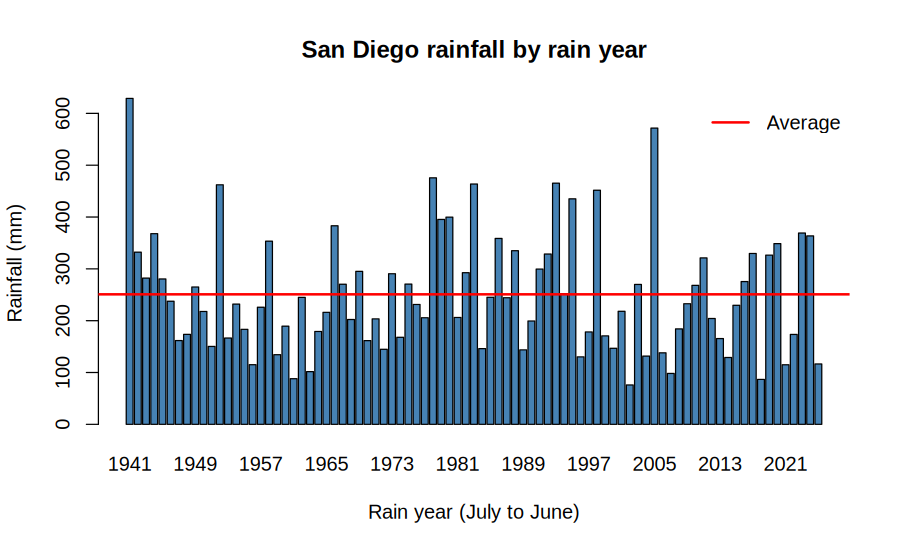

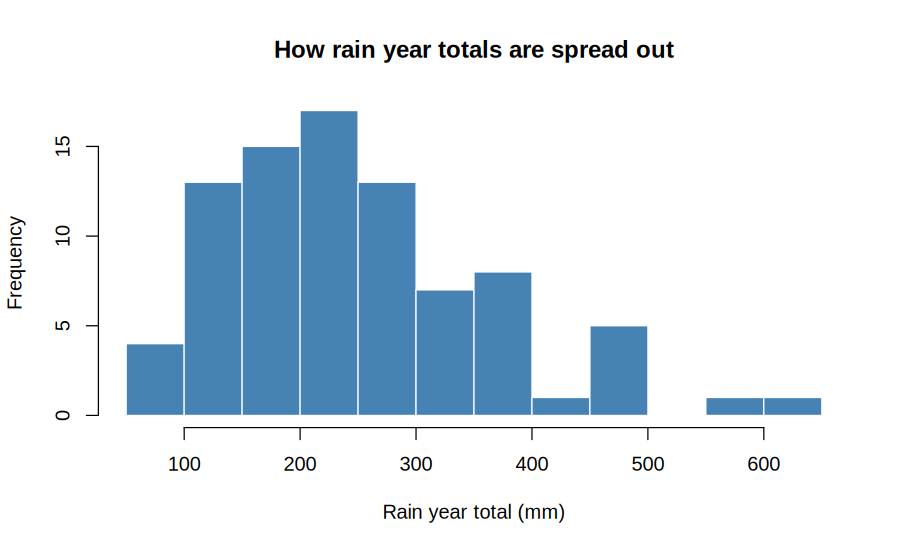

In [25]:
# Rainfall by rain year with the average marked and a histogram of how the yearly totals are spread out
IRdisplay::display_png(file = "figures/rainfall_by_year.png")
IRdisplay::display_png(file = "figures/rainfall_histogram.png")

In [26]:
# Redo the temperature trend with matrices (normal equations and QR)
# and check it against lm().
# Also compares condition numbers for raw vs centered years.
# The "Normal equations failed" message is expected: it shows the
# problem is unstable with raw years once a year squared term is added.
source("03_matrix_least_squares.R")

Station: SAN DIEGO INTERNATIONAL AIRPORT, CA US 
Rows: 31409 
Date range: 1940-01-01 to 2025-12-31 
Calendar days with no row: 3 
[1] "1947-04-06" "1947-04-07" "1947-04-08"
Missing TMAX: 3 
Missing TMIN: 2 
Missing PRCP: 0 

Design matrix: 86 rows by 2 columns

Coefficients from the normal equations:
            [,1]
     -7.84820127
year  0.01291823

Coefficients from lm():
(Intercept)        year 
-7.84820127  0.01291823 

Largest difference: 5.230927e-11 

Coefficients from QR:
                   year 
-7.84820127  0.01291823 

Condition number of X^T X, raw year:      2.51e+10 
Condition number of X^T X, centered year: 6.16e+02 

Normal equations failed with raw years:
   system is computationally singular: reciprocal condition number = 1.26981e-21 

Quadratic fit with centered years (normal equations):
                [,1]
       17.8763320937
year_c  0.0129182289
       -0.0001852245

Quadratic fit from lm():
  (Intercept)        year_c   I(year_c^2) 
17.8763320937  0.0129182289 